# Verification of the wave solver and the interferometry pipeline

This notebook tests the **same code** used by the app (`simulation.py`), independently of the UI.

**Test 1 (solver).** A point source with a Ricker wavelet $w(t)$ in a homogeneous 2D medium. The PDE is

$$u_{tt} + \sigma(\mathbf{x})\,u_t = c^2\nabla^2 u + w(t)\,\delta(\mathbf{x}),\qquad u=u_t=0 \text{ at } t=0,$$

with $\sigma=0$ inside the domain, a sponge layer at the edges, and $u=0$ on the outermost nodes. For an unbounded medium the exact solution is the 2D Green's function convolved with the wavelet:

$$G(r,t)=\frac{H(t-r/c)}{2\pi c^2\sqrt{t^2-r^2/c^2}},\qquad \hat G(r,\omega)=\frac{i}{4c^2}H_0^{(1)}(\omega r/c),\qquad u(r,t)=(G*w)(r,t).$$

We evaluate $u$ in the frequency domain with `scipy.special.hankel1` (this avoids the singularity at the wavefront).
We then check convergence in $\Delta x$ and $\Delta t$, the CFL stability limit, and how well the sponge absorbs.

**Test 2 (interferometry).** For an isotropic ring of uncorrelated sources (radius $R$, unit total intensity), the expected correlation satisfies

$$\frac{d}{dt}C_{AB}(t) = -\frac{1}{4\pi c R}\big[G(r_{AB},t)-G(r_{AB},-t)\big] \quad(\text{band-limited, far field}).$$

We compare the FD-based correlation with (a) the same source sum computed from exact Hankel functions and (b) this Green's function retrieval formula.

**Test 3 (directional sources).** For a von Mises source distribution we compare the travel-time bias measured from the FD correlations with the Hankel-function reference and with the stationary-phase prediction of Weaver et al. (2009).

Units: km, s, km/s. Parameters are at sedimentary-basin scale: $c = 2.2$ km/s and a Ricker peak frequency $f_0 = 2$ Hz (wavelength 1.1 km), typical of high-frequency ambient noise used to image basins.

In [1]:
import numpy as np, matplotlib.pyplot as plt, time
import simulation as S
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
c0, f0 = S.C0, S.F0          # 2.2 km/s, 2 Hz
lam = c0 / f0                  # 1.1 km

## Test 1a: one trace and a snapshot
Grid spacing $\Delta x = 50$ m (22 points per wavelength at $f_0$, and 11 at 4 Hz, the upper end of the Ricker band). We use CFL $= c\Delta t/\Delta x = 0.5$, the value the app uses.

r =   1.0 km   relative L2 error = 0.0076
r =   2.0 km   relative L2 error = 0.0151
r =   3.0 km   relative L2 error = 0.0226


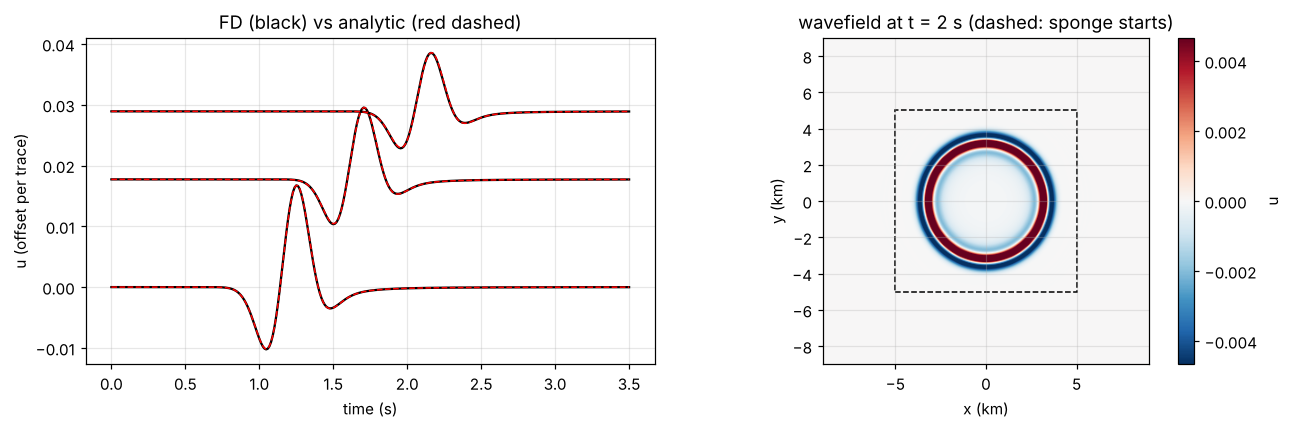

In [2]:
m = S.Model(half_width=5.0)
rs = np.array([1.0, 2.0, 3.0])
it_snap = int(2.25 / m.dt)
t, tr, snaps = S.simulate(m, (0, 0), np.c_[rs, 0 * rs], f0, T=3.5, snapshots=[it_snap])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for i, r in enumerate(rs):
    a = S.analytic_trace(r, t, f0, c0)
    off = 1.5 * np.abs(a).max() * i
    ax[0].plot(t, tr[:, i] + off, "k", lw=1.5)
    ax[0].plot(t, a + off, "r--", lw=1)
    print(f"r = {r:5.1f} km   relative L2 error = {np.linalg.norm(tr[:, i] - a) / np.linalg.norm(a):.4f}")
ax[0].set(xlabel="time (s)", ylabel="u (offset per trace)", title="FD (black) vs analytic (red dashed)")
L = m.x[-1]
im = ax[1].imshow(snaps[it_snap], extent=[-L, L, -L, L], origin="lower", cmap="RdBu_r", vmin=-np.abs(snaps[it_snap]).max() / 2, vmax=np.abs(snaps[it_snap]).max() / 2)
ax[1].add_patch(plt.Rectangle((-5, -5), 10, 10, fill=False, ls="--", color="k"))
ax[1].set(xlabel="x (km)", ylabel="y (km)", title=f"wavefield at t = {it_snap * m.dt:.0f} s (dashed: sponge starts)")
plt.colorbar(im, ax=ax[1], label="u"); plt.tight_layout()

## Test 1b: convergence with grid spacing
We fix a very small time step (CFL $= 0.05$) so the time error is negligible, and refine $\Delta x$. The receiver is at $r = 2$ km, which lies on a grid node for every $\Delta x$ tested. The error measure is the relative L2 misfit of the trace. The stencil is 4th order in space, so we expect a slope close to 4.

In [3]:
def trace_error(dx, cfl, r=2.0, T=2.5):
    m = S.Model(half_width=4.0, dx=dx, cfl=cfl)
    t, tr, _ = S.simulate(m, (0, 0), [[r, 0]], f0, T)
    a = S.analytic_trace(r, t, f0, c0)
    return np.linalg.norm(tr[:, 0] - a) / np.linalg.norm(a), m.dt

dxs = np.array([0.125, 0.1, 0.08, 0.05, 0.04])
err_dx = np.array([trace_error(d, 0.05)[0] for d in dxs])
p_dx = np.polyfit(np.log(dxs), np.log(err_dx), 1)[0]
for d, e in zip(dxs, err_dx): print(f"dx = {1000 * d:4.0f} m  ({c0 / (2 * f0) / d:4.1f} pts/wavelength at {2 * f0:.0f} Hz)   error = {e:.2e}")
print(f"observed order in dx: {p_dx:.2f}")

dx =  125 m  ( 4.4 pts/wavelength at 4 Hz)   error = 7.39e-02
dx =  100 m  ( 5.5 pts/wavelength at 4 Hz)   error = 3.02e-02
dx =   80 m  ( 6.9 pts/wavelength at 4 Hz)   error = 1.24e-02
dx =   50 m  (11.0 pts/wavelength at 4 Hz)   error = 1.84e-03
dx =   40 m  (13.8 pts/wavelength at 4 Hz)   error = 7.25e-04
observed order in dx: 4.05


## Test 1c: convergence with time step
At a fine grid ($\Delta x = 25$ m), we vary CFL from 0.6 down to 0.2. Leapfrog is 2nd order in time, so we expect a slope close to 2 until the remaining spatial error sets a floor.

dt =  6.82 ms   error = 5.95e-03
dt =  5.11 ms   error = 3.30e-03
dt =  3.41 ms   error = 1.40e-03
dt =  2.27 ms   error = 5.62e-04
observed order in dt: 2.15


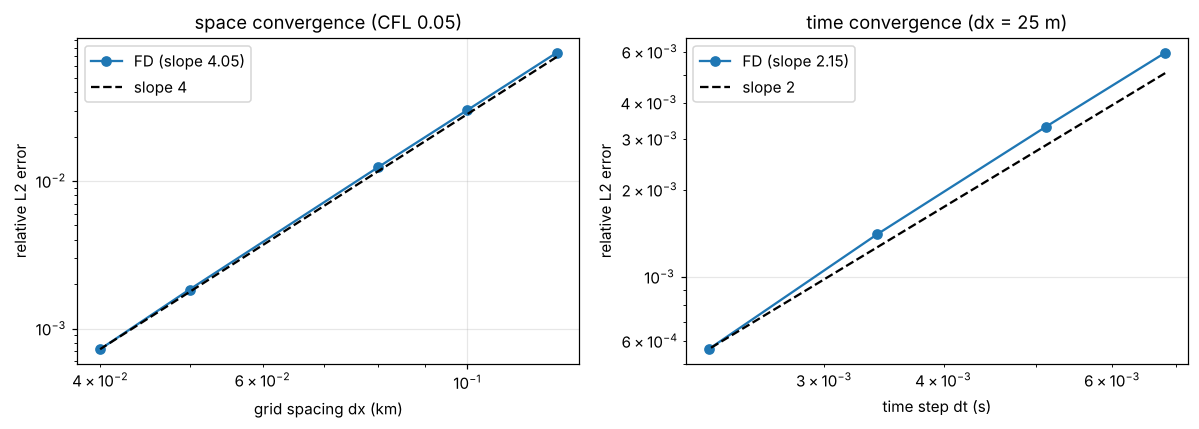

In [4]:
cfls = np.array([0.6, 0.45, 0.3, 0.2])
res = [trace_error(0.025, cf) for cf in cfls]
err_dt, dts = np.array([r[0] for r in res]), np.array([r[1] for r in res])
p_dt = np.polyfit(np.log(dts), np.log(err_dt), 1)[0]
for d, e in zip(dts, err_dt): print(f"dt = {1000 * d:5.2f} ms   error = {e:.2e}")
print(f"observed order in dt: {p_dt:.2f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].loglog(dxs, err_dx, "o-", label=f"FD (slope {p_dx:.2f})")
ax[0].loglog(dxs, err_dx[-1] * (dxs / dxs[-1]) ** 4, "k--", label="slope 4")
ax[0].set(xlabel="grid spacing dx (km)", ylabel="relative L2 error", title="space convergence (CFL 0.05)")
ax[1].loglog(dts, err_dt, "o-", label=f"FD (slope {p_dt:.2f})")
ax[1].loglog(dts, err_dt[-1] * (dts / dts[-1]) ** 2, "k--", label="slope 2")
ax[1].set(xlabel="time step dt (s)", ylabel="relative L2 error", title="time convergence (dx = 25 m)")
for a in ax: a.legend()
plt.tight_layout()

## Test 1d: stability limit
For leapfrog with the 4th-order Laplacian in 2D, the scheme is stable for $c\Delta t/\Delta x \le \sqrt{3/8} \approx 0.612$. Just above that limit, the solution should grow without bound.

In [5]:
for cfl in [0.60, 0.62]:
    m = S.Model(half_width=2.5, cfl=cfl)
    t, tr, _ = S.simulate(m, (0, 0), [[1.0, 0]], f0, T=20)
    print(f"CFL = {cfl:.2f}:  max |u| over the last 5 s = {np.abs(tr[t > 15]).max():.2e}")

CFL = 0.60:  max |u| over the last 5 s = 3.47e-06


CFL = 0.62:  max |u| over the last 5 s = 6.46e+180


## Test 1e: absorbing (sponge) boundary
Any reflection from the edges would act as a spurious noise source in the correlations. We measure it by comparing a small domain against a domain large enough that no reflection reaches the receivers within the record. The difference is the reflected energy.

In [6]:
rec = [[3.5, 0], [0, 0], [-2, 2]]
_, ref, _ = S.simulate(S.Model(half_width=18), (0, 0), rec, f0, 10)
for ns in [40, 80]:
    t, tr, _ = S.simulate(S.Model(half_width=4, n_sponge=ns), (0, 0), rec, f0, 10)
    refl = np.abs(tr - ref).max() / np.abs(ref[:, 0]).max()
    print(f"sponge {ns} cells ({ns * S.DX:.1f} km = {ns * S.DX / lam:.1f} wavelengths): max reflection = {100 * refl:.2f}% of direct wave at 3.5 km")

sponge 40 cells (2.0 km = 1.8 wavelengths): max reflection = 5.20% of direct wave at 3.5 km


sponge 80 cells (4.0 km = 3.6 wavelengths): max reflection = 1.02% of direct wave at 3.5 km


## Test 2: Green's function retrieval from an isotropic noise ring
Stations are $r = 3$ km apart (2.7 wavelengths), and $N$ sources sit on a ring of radius $R = 12$ km, spaced 150 m apart (less than $\lambda/2$ across the band). There are two FD runs (an impulse at A and an impulse at B), and reciprocity turns them into all source-receiver Green's functions. Before comparing, every correlation is whitened and band-passed around $f_c = 2$ Hz.

2 FD runs: 12.9 s, grid 701^2, 865 steps, 503 ring sources
FD vs Hankel-sum correlation: relative L2 error = 0.0135
FD dC/dt vs -(G(t)-G(-t))/(4 pi c R): relative L2 error = 0.0172


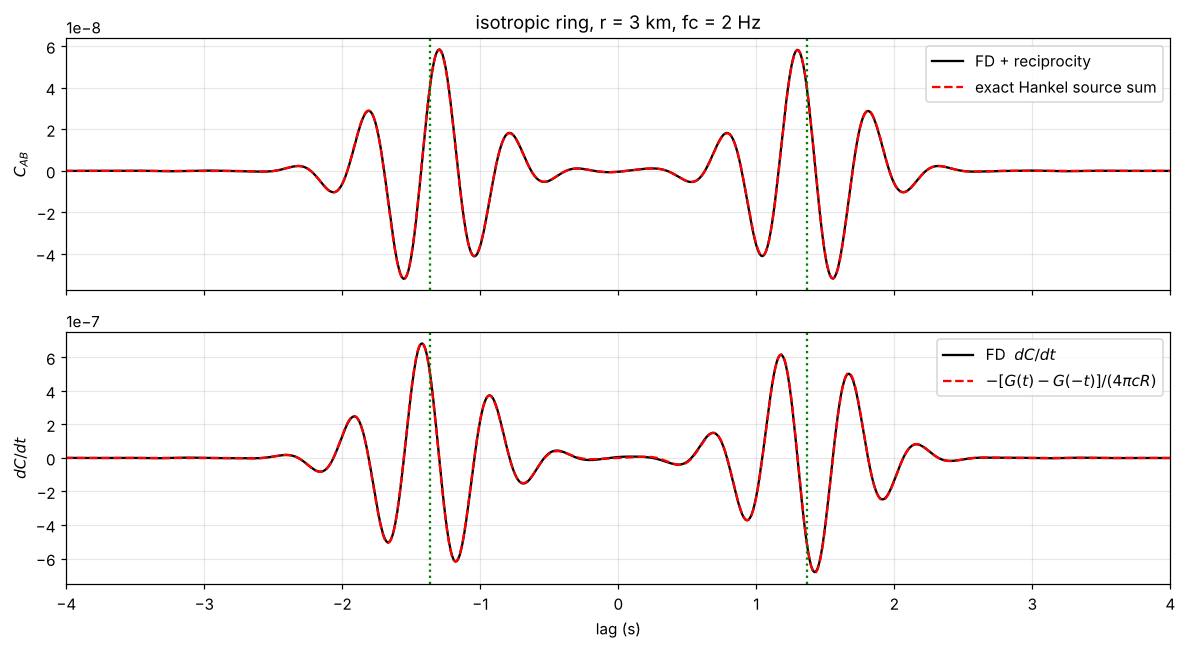

In [7]:
t0 = time.time()
exp = S.PairExperiment(S.Model(), r=3.0, R=S.RING_R, f0=f0)
print(f"2 FD runs: {time.time() - t0:.1f} s, grid {exp.model.n}^2, {exp.t.size} steps, {exp.theta.size} ring sources")

fc, w_iso = 2.0, exp.weights()
C_fd = exp.correlate(w_iso, fc)
C_hk = S.hankel_correlation(exp, w_iso, fc)

# Green's function retrieval: dC/dt = -(G(t) - G(-t)) / (4 pi c R), same band-pass
f, R = exp.f, S.RING_R
band = np.exp(-0.5 * ((f - fc) / (0.2 * fc)) ** 2) * exp.W2 / (exp.W2 + 1e-3 * exp.W2.max())
G = S.greens_hat(exp.r, f, c0)
rhs = np.fft.fftshift(np.fft.irfft(-(G - np.conj(G)) / (4 * np.pi * c0 * R) * band, exp.nfft))
dCdt = np.gradient(C_fd, exp.model.dt)

e_hk = np.linalg.norm(C_fd - C_hk) / np.linalg.norm(C_hk)
e_gf = np.linalg.norm(dCdt - rhs) / np.linalg.norm(rhs)
print(f"FD vs Hankel-sum correlation: relative L2 error = {e_hk:.4f}")
print(f"FD dC/dt vs -(G(t)-G(-t))/(4 pi c R): relative L2 error = {e_gf:.4f}")

fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
ax[0].plot(exp.lags, C_fd, "k", label="FD + reciprocity")
ax[0].plot(exp.lags, C_hk, "r--", label="exact Hankel source sum")
ax[0].set(ylabel=r"$C_{AB}$", title="isotropic ring, r = 3 km, fc = 2 Hz")
ax[1].plot(exp.lags, dCdt, "k", label=r"FD  $dC/dt$")
ax[1].plot(exp.lags, rhs, "r--", label=r"$-[G(t)-G(-t)]/(4\pi cR)$")
ax[1].set(xlabel="lag (s)", ylabel=r"$dC/dt$", xlim=(-4, 4))
for a in ax:
    a.legend(loc="upper right"); [a.axvline(s * exp.r / c0, color="g", ls=":") for s in (-1, 1)]
plt.tight_layout()

## Test 3: travel-time bias for directional noise
We use the noise intensity $B(\theta)=\epsilon/2\pi + (1-\epsilon)\,\mathrm{vM}(\theta;\theta_0,\kappa)$ with $\epsilon=0$. For each source pattern we measure the travel-time shift of each correlation branch relative to the isotropic correlation, using waveform cross-correlation in a window of ±1.5 periods. We compare three versions:
* FD correlations (what the app uses),
* the exact Hankel-function source sum (the same discrete ring, no FD error),
* the stationary-phase formula $\delta t = -B''(\theta_e)/(2\omega^2 t\,B(\theta_e))$ at the endfire direction $\theta_e$ that feeds each branch (Weaver et al. 2009).

We use two dominant directions: noise arriving from 45° off the pair axis, and broadside noise (90°).

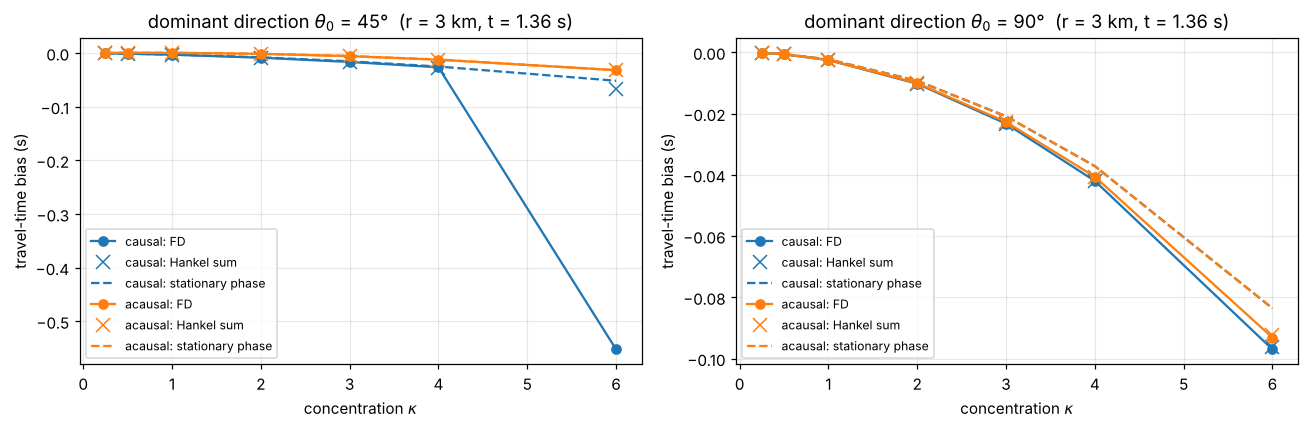

In [8]:
kappas = np.array([0.25, 0.5, 1, 2, 3, 4, 6])
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
Cref_fd, Cref_hk = exp.correlate(w_iso, fc), S.hankel_correlation(exp, w_iso, fc)
for a, th_deg in zip(ax, [45, 90]):
    th = np.radians(th_deg)
    for br, col in [("causal", "C0"), ("acausal", "C1")]:
        fd, hk, wv = [], [], []
        for k in kappas:
            w = exp.weights(th, k, 0.0)
            fd.append(exp.measure(exp.correlate(w, fc), Cref_fd, fc)["dt_" + br])
            hk.append(exp.measure(S.hankel_correlation(exp, w, fc), Cref_hk, fc)["dt_" + br])
            wv.append(exp.weaver_prediction(th, k, 0.0, fc)["dt_" + br])
        a.plot(kappas, fd, "o-", color=col, label=f"{br}: FD")
        a.plot(kappas, hk, "x", color=col, ms=9, label=f"{br}: Hankel sum")
        a.plot(kappas, wv, "--", color=col, label=f"{br}: stationary phase")
    a.set(xlabel=r"concentration $\kappa$", ylabel="travel-time bias (s)",
          title=rf"dominant direction $\theta_0$ = {th_deg}°  (r = {exp.r:.0f} km, t = {exp.r / c0:.2f} s)")
    a.legend(fontsize=8)
plt.tight_layout()

## Discussion

* **Solver accuracy.** The FD traces match the analytic Green's function. The error falls with an observed order close to 4 in $\Delta x$ and close to 2 in $\Delta t$, as expected for the 4th-order Laplacian with leapfrog time stepping. At the app's settings ($\Delta x$ = 50 m, CFL 0.5), the remaining error is a few percent and grows with distance. It is mostly time-step dispersion, which makes waves at the upper end of the band travel slightly slow. Halving the time step would reduce it, at twice the cost.
* **Why dispersion does not pollute the bias.** The app always reports bias as a shift relative to the *isotropic* correlation computed with the same FD runs. The numerical dispersion is therefore common to both and cancels. Test 2 shows that the absolute FD travel time is still accurate to about 0.1%.
* **Stability.** The run is stable at CFL 0.60 and blows up at 0.62, consistent with the limit $\sqrt{3/8}$.
* **Boundaries.** A quadratic damping sponge 80 cells thick (about 3.6 wavelengths) reflects about 1% or less. A 40-cell sponge reflects several percent. Simple damping layers always reflect a little; a PML would do better but is more complex.
* **Interferometry.** The isotropic ring gives the theoretical result $dC/dt \propto -[G(t)-G(-t)]$. The remaining misfit comes from the far-field approximation in the formula, the finite ring, and FD dispersion.
* **Directional bias.** For moderate concentration, FD and the exact Hankel sum agree closely. Both follow the stationary-phase prediction, so the bias is controlled by the *curvature* of $B(\theta)$ at the endfire directions. When the noise is strongly concentrated, the formula fails: it assumes $B$ varies slowly across the Fresnel zone, and the branch fed by the weak side carries almost no energy. For very large $\kappa$ that weak branch falls below the FD noise floor (sponge reflections and dispersion at the 1% level). This is visible as the FD causal pick leaving the Hankel curve at $\kappa = 6$ for $\theta_0 = 45°$. Real data hit the same limit: the weak branch drops below the noise.
* **Limitations.** This is a scalar (acoustic or membrane) model standing in for fundamental-mode Rayleigh waves, with no dispersion of physical origin. Sources are point sources in the far field ($R \approx 11\lambda$).